In [1]:
pip install pandas numpy matplotlib scipy


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.stats as stats

In [14]:
# read the movies data
airport = pd.read_csv("/content/drive/MyDrive/Intro to Data Science HW/airport_routes.csv")
movies

,Airport,NumberOfRoutes
0,AAE,9
1,AAL,20
2,AAN,2
3,AAQ,3
4,AAR,8
...,...,...
3404,ZUH,60
3405,ZUM,2
3406,ZVK,3
3407,ZYI,15


In [15]:
# max NumberOfRoutes
mov_max = airport['NumberOfRoutes'].max()
mov_max

915

In [16]:
# min NumberOfRoutes
mov_min = airport['NumberOfRoutes'].min()
mov_min

1

In [17]:
# mean NumberOfRoutes
routes_mean = airport['NumberOfRoutes'].mean()
routes_mean

19.845115869756526

In [18]:
# std_dev vote for movies
mov_std = airport['NumberOfRoutes'].std()
mov_std

53.50646658403505

In [20]:
#  rows we have
mov_mount = len(airport)
mov_mount

3409

In [21]:
# lambda
mov_lamda = 1/mov_mean
mov_lamda

0.050390232365635904

In [22]:
# alpha

total = 0

for num in movies["NumberOfRoutes"]:
  total += np.log(num/mov_min)
mov_alpha = 1+(mov_mount/total)
mov_alpha

1.612091630402377

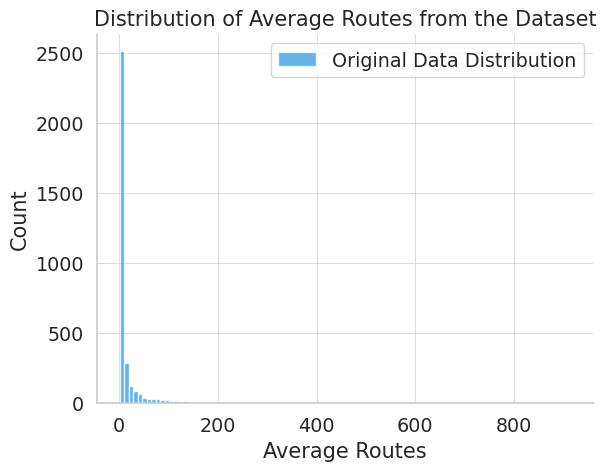

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns  # seaborn library for aesthetic enhancements

# Setting style using seaborn
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.25, rc={"grid.linewidth": 0.5, 'lines.linewidth': 2})

# Creating the histogram
plt.hist(movies['NumberOfRoutes'], bins=100, color="#3498db", alpha=0.75)  # using a muted blue color and some transparency

# Setting the labels, title, and legend
plt.xlabel("Average Routes")
plt.ylabel("Count")
plt.title("Distribution of Average Routes from the Dataset")
plt.legend(labels=["Original Data Distribution"])

# Removing top and right spines for aesthetics
sns.despine(top=True, right=True)

# Displaying the plot
plt.show()


# **Power law distribution**

Text(0, 0.5, 'Count')

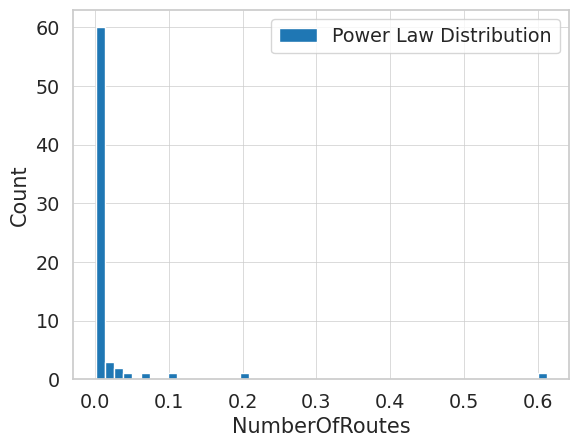

In [25]:
#  power law dist
def powerlawDist(x,alpha,mn):
  return ((alpha-1)/mn)*((x/mn)**(-alpha))

#  power law dist
mov_powerlaw_theory = []
x = []
for i in range(1,100):
  x += [i]
  mov_powerlaw_theory += [powerlawDist(i,mov_alpha,mov_min)]

plt.hist(mov_powerlaw_theory[0:70], bins=50)
plt.legend(labels=["Power Law Distribution"])
plt.xlabel("NumberOfRoutes")
plt.ylabel("Count")

# **Exponential distribution**

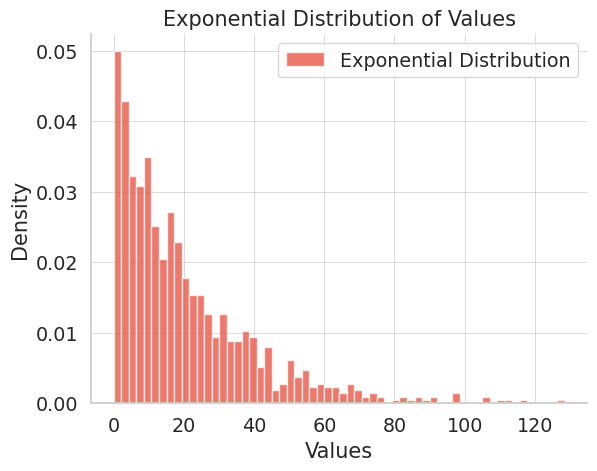

In [27]:
mov_lamda = 0.05

mov_exponential_thy = np.random.exponential(scale=1/mov_lamda, size=1000)

# Using Seaborn for aesthetic enhancements
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.25, rc={"grid.linewidth": 0.5, 'lines.linewidth': 2})

# Histogram for the exponential distribution
plt.hist(mov_exponential_thy, bins=60, color='#e74c3c', alpha=0.75, density=True)  # Using a shade of red and setting density=True

plt.legend(labels=["Exponential Distribution"])
plt.xlabel("Values")  # Changed to a more general label as it may not be "Average Ratings"
plt.ylabel("Density")  # Changed label to "Density" when using density=True
plt.title("Exponential Distribution of Values")  # Adjust the title accordingly

sns.despine(top=True, right=True)  # Removing top and right spines for aesthetics

plt.show()


# **Uniform distribution**

In [28]:
# Uniform distribution
def uniformDist(x, mn, mx):
  return 1/(mn-mx)

Text(0, 0.5, 'Count')

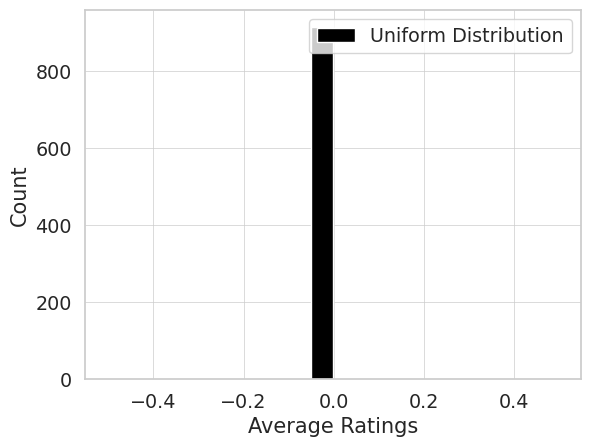

In [29]:
# Uniform distribution

mov_uniform_thy = []
x = []
for i in range(round(mov_min),round(mov_max)):
  x += [i]
  mov_uniform_thy += [uniformDist(i,mov_min,mov_max)]

plt.hist(mov_uniform_thy, bins=20, color="black")
plt.legend(labels=["Uniform Distribution"])
plt.xlabel("Average Ratings")
plt.ylabel("Count")

# **Normal distribution**

In [30]:
# normal distribution
mov_mean

19.845115869756526

In [31]:
# normal distribution
mov_std

53.50646658403505

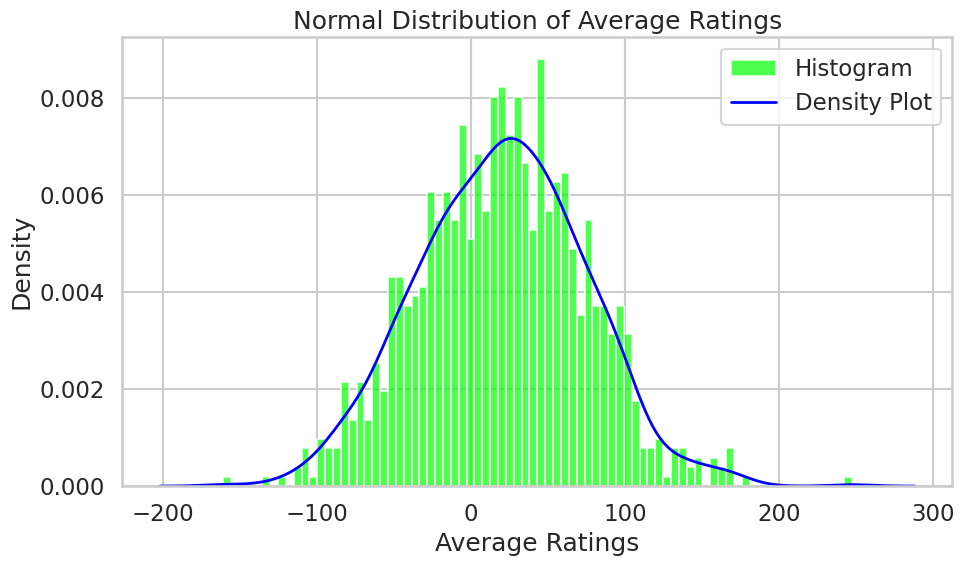

In [32]:
# Generating normal distribution data
mov_normal_theory = np.random.normal(loc=mov_mean, scale=mov_std, size=1000)

# Setting up the style and context of the plot using seaborn
sns.set_style("whitegrid")
sns.set_context("talk")  # talk context is for presentations

# Creating the histogram
plt.figure(figsize=(10, 6))
plt.hist(mov_normal_theory, bins=80, color="lime", alpha=0.7, density=True, label="Histogram")

# Adding a density plot
sns.kdeplot(mov_normal_theory, color="blue", linewidth=2, label="Density Plot")

# Adding labels, title, legend, and other aesthetics
plt.title("Normal Distribution of Average Ratings")
plt.xlabel("Average Ratings")
plt.ylabel("Density")
plt.legend(loc="upper right")
plt.tight_layout()

# Displaying the plot
plt.show()

# **Discussing the airport route data distribution**

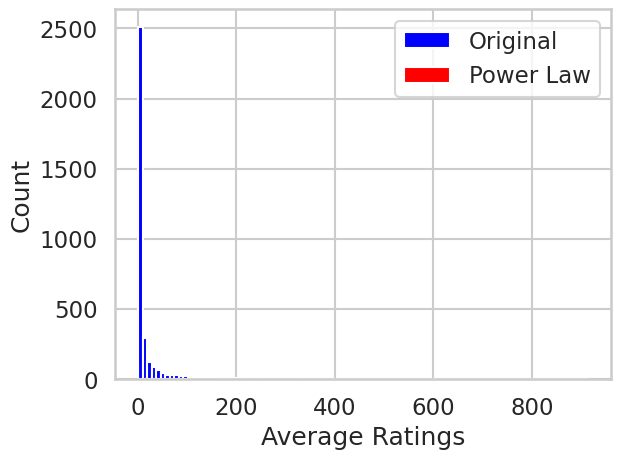

In [36]:
x = airport['NumberOfRoutes']
y = mov_powerlaw_theory[0:3000]

plt.hist(x, label='Original',  bins=100, color="blue")
plt.hist(y, label='Power Law',  bins=10, color="red")
# plt.hist(x)
# plt.hist(y)
plt.legend(labels=["Original Vs Power law Distribution"])
plt.xlabel("Average Ratings")
plt.ylabel("Count")
plt.legend()
plt.show()